Starting merge. TARGET_SIZE = None
Detected DRIVE root: /content/drive/MyDrive/DRIVE
Detected CHASE_DB1 root: /content/drive/MyDrive/CHASE_DB1

Processing DRIVE root: /content/drive/MyDrive/DRIVE
Detected layout: split_manual
Images dir: /content/drive/MyDrive/DRIVE/training/images
Masks dir : /content/drive/MyDrive/DRIVE/training/1st_manual


Merging DRIVE:   0%|          | 0/20 [00:00<?, ?it/s]/tmp/ipython-input-657209025.py:71: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(bin_arr, mode="L")
Merging DRIVE: 100%|██████████| 20/20 [00:05<00:00,  3.93it/s]


Saved DRIVE pairs: 20

Processing CHASE_DB1 root: /content/drive/MyDrive/CHASE_DB1
Detected layout: heuristic
Images dir: /content/drive/MyDrive/CHASE_DB1
Masks dir : /content/drive/MyDrive/CHASE_DB1


Merging CHASE_DB1: 100%|██████████| 28/28 [00:12<00:00,  2.19it/s]

Saved CHASE_DB1 pairs: 28
Meta saved to: /content/drive/MyDrive/Vessel_Merged/meta.csv
DONE. Total merged pairs: 48
images: /content/drive/MyDrive/Vessel_Merged/images
masks : /content/drive/MyDrive/Vessel_Merged/masks

Showing one random sample from merged output:
Sample: /images/img_000040.png /masks/mask_000040.png


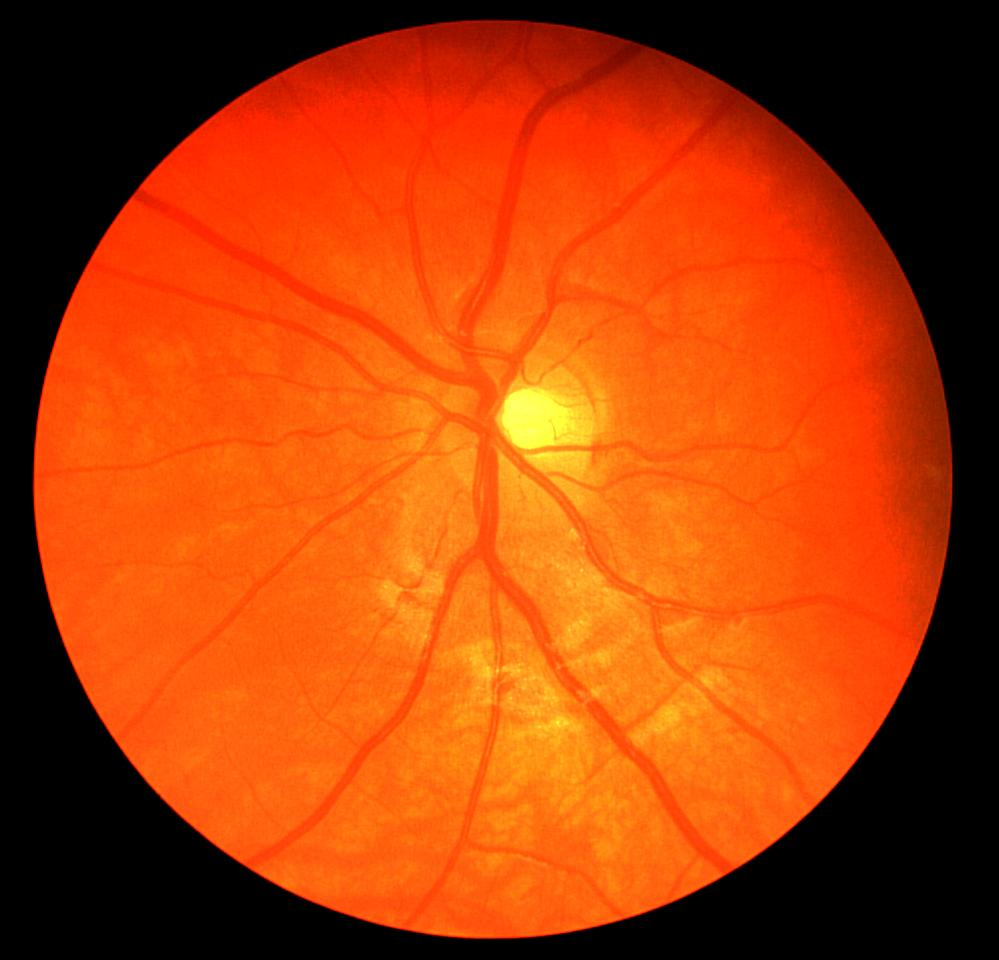

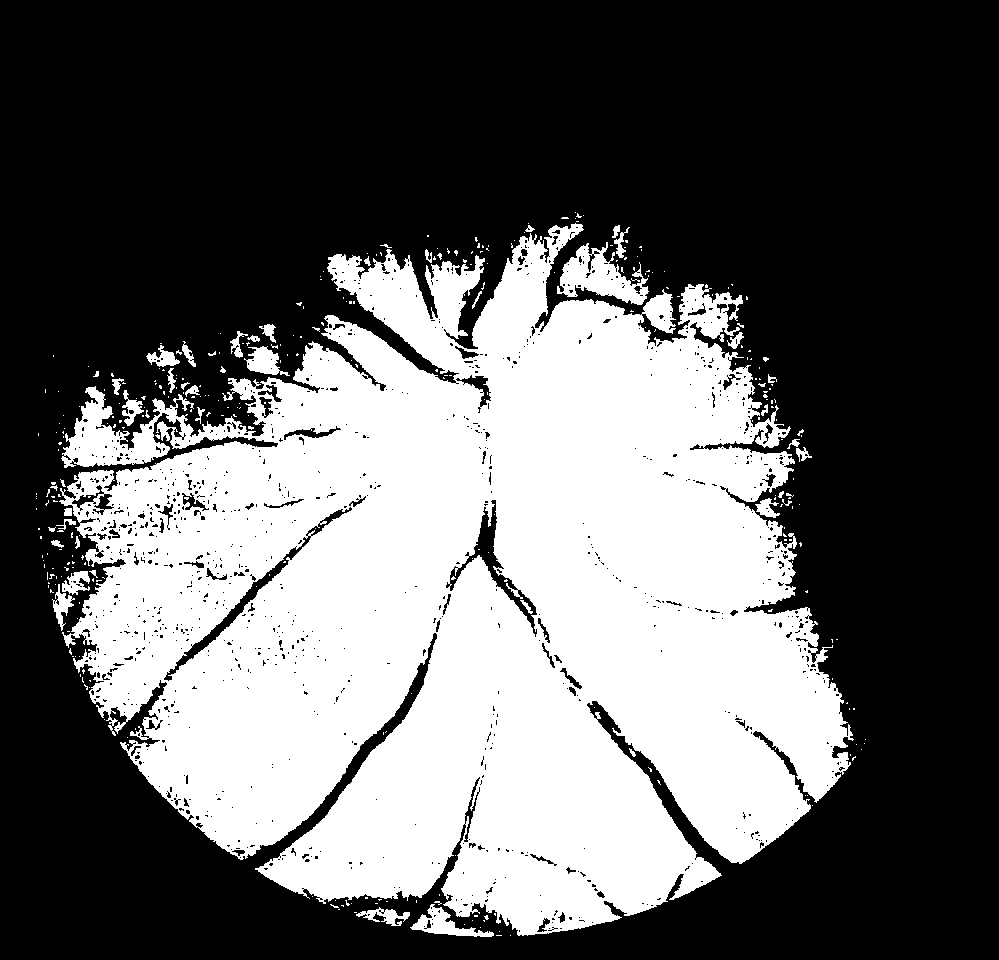

In [ ]:


import os
import sys
import shutil
import glob
import random
from pathlib import Path
from tqdm import tqdm
import pandas as pd
from PIL import Image, ImageOps
import numpy as np

# ------------- Config -------------
# Where to put merged output on Drive
OUT_ROOT = "/content/drive/MyDrive/Vessel_Merged"

# Common dataset roots on Drive (adjust if your folders are named differently)
CANDIDATE_DRIVE = [
    "/content/drive/MyDrive/DRIVE",
    "/content/drive/MyDrive/drive",
    "/content/drive/MyDrive/DRIVE-dataset",
]
CANDIDATE_CHASE = [
    "/content/drive/MyDrive/CHASE_DB1",
    "/content/drive/MyDrive/CHASE",
    "/content/drive/MyDrive/CHASE-DB1",
]

# If you want to resize everything: set either None (keep original) or (H, W)
# e.g., TARGET_SIZE = (512,512)
TARGET_SIZE = None

# File extensions to accept for images and masks
IMG_EXTS = {".jpg", ".jpeg", ".png", ".ppm", ".tif", ".tiff", ".bmp"}
MASK_EXTS = {".gif", ".png", ".bmp", ".jpg", ".jpeg", ".tif", ".tiff"}

# Make reproducible
random.seed(42)

# ------------- Helpers -------------
def ensure_drive_mounted():
    # For notebooks: mount if not mounted — but assume user has already mounted.
    if not os.path.exists("/content/drive"):
        raise RuntimeError("Google Drive does not appear to be mounted at /content/drive. Mount it first.")

def safe_mkdir(p):
    os.makedirs(p, exist_ok=True)

def normalize_img(img: Image.Image, target_size=None):
    """Return RGB image (PIL). Convert if grayscale, and optionally resize with bicubic."""
    if img.mode == "L":
        img = img.convert("RGB")
    elif img.mode == "RGBA":
        img = img.convert("RGB")
    # optionally resize
    if target_size is not None:
        img = ImageOps.fit(img, target_size, method=Image.BICUBIC)
    return img

def process_mask_image(img: Image.Image, target_size=None, thr=128):
    """
    Convert a mask image (possibly GIF, RGB) to single-channel binary mask (PIL L, 0/255).
    - thr: threshold to binarize
    """
    # Convert to grayscale
    m = img.convert("L")
    if target_size is not None:
        m = ImageOps.fit(m, target_size, method=Image.NEAREST)
    arr = np.array(m)
    # threshold (consider >128 as vessel)
    bin_arr = (arr > thr).astype(np.uint8) * 255
    return Image.fromarray(bin_arr, mode="L")

def find_first_existing(paths):
    for p in paths:
        if p and os.path.exists(p):
            return p
    return None

def list_files_recursive(folder, exts):
    out = []
    for root, dirs, files in os.walk(folder):
        for f in files:
            if os.path.splitext(f)[1].lower() in exts:
                out.append(os.path.join(root, f))
    return sorted(out)

# ------------- DRIVE Processing -------------
def detect_drive_layout(drive_root):
    """
    Detect common DRIVE layouts and return (list_of_image_paths, list_of_mask_paths)
    Common DRIVE layouts:
      - DRIVE/training/images/*.tif  and DRIVE/training/1st_manual/*.gif  (or similar)
      - DRIVE/test/images/*.tif and DRIVE/test/1st_manual/*.gif
      - DRIVE/images/ and DRIVE/masks/
      - DRIVE/training/images/*.tif  with masks in DRIVE/training/mask/...
    """
    drive_root = Path(drive_root)
    candidates = []

    # pattern 1: training/test images + 1st_manual
    for split in ("training", "test"):
        img_dir = drive_root / split / "images"
        mask_dir = drive_root / split / "1st_manual"
        if img_dir.exists() and mask_dir.exists():
            candidates.append(("split_manual", str(img_dir), str(mask_dir)))

    # pattern 2: images/ and masks/ at top-level
    img_dir = drive_root / "images"
    mask_dir = drive_root / "masks"
    if img_dir.exists() and mask_dir.exists():
        candidates.append(("images_masks", str(img_dir), str(mask_dir)))

    # pattern 3: top-level test/training masks under test/mask or training/mask
    for split in ("training", "test"):
        img_dir = drive_root / split / "images"
        mask_dir = drive_root / split / "mask"
        if img_dir.exists() and mask_dir.exists():
            candidates.append(("split_mask", str(img_dir), str(mask_dir)))

    # fallback: scan recursively for image files and mask files naming patterns
    if not candidates:
        # attempt to heuristically find
        img_paths = list_files_recursive(str(drive_root), IMG_EXTS)
        mask_paths = list_files_recursive(str(drive_root), MASK_EXTS)
        if img_paths and mask_paths:
            # choose root and return file lists later
            candidates.append(("heuristic", str(drive_root), str(drive_root)))

    return candidates

def process_drive(drive_root, out_root, counter_start=0, target_size=None):
    """
    Process DRIVE dataset. Returns new counter.
    """
    print(f"\nProcessing DRIVE root: {drive_root}")
    candidates = detect_drive_layout(drive_root)
    if not candidates:
        print("⚠️ Could not detect DRIVE layout automatically. Please check the folder structure.")
        return counter_start

    # Prefer explicit split_manual candidate if present
    chosen = None
    for c in candidates:
        if c[0] == "split_manual":
            chosen = c; break
    if chosen is None:
        chosen = candidates[0]

    style, img_dir, mask_dir = chosen
    print("Detected layout:", style)
    print("Images dir:", img_dir)
    print("Masks dir :", mask_dir)

    # collect image files
    img_files = list_files_recursive(img_dir, IMG_EXTS)
    mask_files = list_files_recursive(mask_dir, MASK_EXTS)

    # create mapping from stem -> path for masks (stem normalized)
    def stem_key(p):
        return Path(p).stem.lower().replace("_manual", "").replace("_mask", "").replace("1st_manual", "")

    mask_map = {stem_key(p): p for p in mask_files}

    out_imgs = Path(out_root) / "images"
    out_masks = Path(out_root) / "masks"
    ensure_drive_mounted()
    safe_mkdir(out_imgs)
    safe_mkdir(out_masks)

    meta_rows = []
    counter = counter_start

    for p in tqdm(img_files, desc="Merging DRIVE"):
        stem = stem_key(p)
        # try to find corresponding mask by matching stems
        # try various possibilities
        mask_path = None
        # direct stem
        if stem in mask_map:
            mask_path = mask_map[stem]
        else:
            # try using only digits in name (DRIVE uses numbers)
            digits = ''.join(filter(str.isdigit, stem))
            for k in mask_map:
                if digits and digits in k:
                    mask_path = mask_map[k]; break
        if mask_path is None:
            # Skip unpaired (log)
            # print("No mask for image:", p)
            continue

        # load image and mask, convert, optionally resize, save to out
        try:
            im = Image.open(p)
            im = normalize_img(im, target_size)
            m = Image.open(mask_path)
            m = process_mask_image(m, target_size)
        except Exception as e:
            print("Error reading:", p, mask_path, e)
            continue

        img_name = f"img_{counter:06d}.png"
        mask_name = f"mask_{counter:06d}.png"
        im.save(out_imgs / img_name)
        m.save(out_masks / mask_name)

        meta_rows.append({
            "id": counter,
            "source": "DRIVE",
            "orig_img": p,
            "orig_mask": mask_path,
            "out_img": str(out_imgs / img_name),
            "out_mask": str(out_masks / mask_name)
        })
        counter += 1

    print(f"Saved DRIVE pairs: {counter - counter_start}")
    return counter, meta_rows

# ------------- CHASE_DB1 Processing -------------
def detect_chase_layout(chase_root):
    """
    Common CHASE layout:
     - CHASE_DB1/img/*.jpg and CHASE_DB1/mask/*.gif
     - CHASE_DB1/images/ and CHASE_DB1/masks/
    """
    chase_root = Path(chase_root)
    candidates = []

    # typical: img/ and mask/
    img_dir = chase_root / "img"
    mask_dir = chase_root / "mask"
    if img_dir.exists() and mask_dir.exists():
        candidates.append(("img_mask", str(img_dir), str(mask_dir)))

    # alternate:
    img_dir = chase_root / "images"
    mask_dir = chase_root / "masks"
    if img_dir.exists() and mask_dir.exists():
        candidates.append(("images_masks", str(img_dir), str(mask_dir)))

    # fallback: any images and any masks recursively
    if not candidates:
        img_paths = list_files_recursive(str(chase_root), IMG_EXTS)
        mask_paths = list_files_recursive(str(chase_root), MASK_EXTS)
        if img_paths and mask_paths:
            candidates.append(("heuristic", str(chase_root), str(chase_root)))
    return candidates

def process_chase(chase_root, out_root, counter_start=0, target_size=None):
    print(f"\nProcessing CHASE_DB1 root: {chase_root}")
    candidates = detect_chase_layout(chase_root)
    if not candidates:
        print(" Could not detect CHASE layout automatically. Please check the folder structure.")
        return counter_start

    chosen = candidates[0]
    style, img_dir, mask_dir = chosen
    print("Detected layout:", style)
    print("Images dir:", img_dir)
    print("Masks dir :", mask_dir)

    img_files = list_files_recursive(img_dir, IMG_EXTS)
    mask_files = list_files_recursive(mask_dir, MASK_EXTS)

    # Create mapping based on stem -> mask
    mask_map = {Path(p).stem.lower(): p for p in mask_files}

    out_imgs = Path(out_root) / "images"
    out_masks = Path(out_root) / "masks"
    safe_mkdir(out_imgs)
    safe_mkdir(out_masks)

    meta_rows = []
    counter = counter_start

    for p in tqdm(img_files, desc="Merging CHASE_DB1"):
        stem = Path(p).stem.lower()
        mask_path = mask_map.get(stem)
        if mask_path is None:
            # CHECK: some CHASE masks contain suffixes, try loosened match
            for k in mask_map:
                if stem.startswith(k) or k.startswith(stem) or k in stem or stem in k:
                    mask_path = mask_map[k]; break
        if mask_path is None:
            # try numeric matching
            digits = ''.join(filter(str.isdigit, stem))
            for k in mask_map:
                if digits and digits in ''.join(filter(str.isdigit, k)):
                    mask_path = mask_map[k]; break
        if mask_path is None:
            # skip if no mask
            continue

        try:
            im = Image.open(p)
            im = normalize_img(im, target_size)
            m = Image.open(mask_path)
            m = process_mask_image(m, target_size)
        except Exception as e:
            print("Error reading:", p, mask_path, e)
            continue

        img_name = f"img_{counter:06d}.png"
        mask_name = f"mask_{counter:06d}.png"
        im.save(out_imgs / img_name)
        m.save(out_masks / mask_name)

        meta_rows.append({
            "id": counter,
            "source": "CHASE_DB1",
            "orig_img": p,
            "orig_mask": mask_path,
            "out_img": str(out_imgs / img_name),
            "out_mask": str(out_masks / mask_name)
        })
        counter += 1

    print(f"Saved CHASE_DB1 pairs: {counter - counter_start}")
    return counter, meta_rows

# ------------- Main runner -------------
def merge_datasets(drive_root_candidates, chase_root_candidates, out_root, target_size=None):
    ensure_drive_mounted()
    safe_mkdir(out_root)
    safe_mkdir(os.path.join(out_root, "images"))
    safe_mkdir(os.path.join(out_root, "masks"))

    # find existing candidate roots
    drive_root = find_first_existing(drive_root_candidates)
    chase_root = find_first_existing(chase_root_candidates)

    print("Detected DRIVE root:", drive_root)
    print("Detected CHASE_DB1 root:", chase_root)

    counter = 0
    meta = []

    if drive_root:
        c, rows = process_drive(drive_root, out_root, counter_start=counter, target_size=target_size)
        counter = c
        meta.extend(rows)
    else:
        print("No DRIVE root found; skipping DRIVE.")

    if chase_root:
        c, rows = process_chase(chase_root, out_root, counter_start=counter, target_size=target_size)
        counter = c
        meta.extend(rows)
    else:
        print("No CHASE_DB1 root found; skipping CHASE_DB1.")

    # Save meta.csv
    if meta:
        df = pd.DataFrame(meta)
        meta_csv = os.path.join(out_root, "meta.csv")
        df.to_csv(meta_csv, index=False)
        print("Meta saved to:", meta_csv)
    else:
        print("No pairs merged; meta not saved.")

    print("DONE. Total merged pairs:", counter)
    print("images:", os.path.join(out_root, "images"))
    print("masks :", os.path.join(out_root, "masks"))
    return out_root

# ------------- Sample display -------------
def show_random_sample(out_root):
    from IPython.display import display
    imgs = sorted(glob.glob(os.path.join(out_root, "images", "*.png")))
    masks = sorted(glob.glob(os.path.join(out_root, "masks", "*.png")))
    if not imgs or not masks:
        print("No merged images/masks to show.")
        return
    idx = random.randrange(len(imgs))
    im_p = imgs[idx]
    mask_p = masks[idx]
    im = Image.open(im_p)
    m = Image.open(mask_p)
    print("Sample:", im_p.replace(out_root,""), mask_p.replace(out_root,""))
    display(im)
    display(m)

# ------------- Execute -------------
if __name__ == "__main__":
    # mount drive BEFORE running this cell (or uncomment below line)
    # from google.colab import drive; drive.mount('/content/drive')

    print("Starting merge. TARGET_SIZE =", TARGET_SIZE)
    out = merge_datasets(CANDIDATE_DRIVE, CANDIDATE_CHASE, OUT_ROOT, target_size=TARGET_SIZE)
    print("\nShowing one random sample from merged output:")
    show_random_sample(out)
